# IHLT Project: Semantic Textual Similarity

**Students:** _\_\_\_\_\__ and _\_\_\_\_\__

This notebook builds a system for the **Semantic Textual Similarity (STS)** task of SemEval 2012 (Task 6): given two sentences, predict how similar their meaning is, from 0 (different topics) to 5 (completely equivalent).

The system extracts similarity features from each pair of sentences and learns to combine them with a regression model trained on the training data of the task. Following the statement of the project, we explore:

1. **Lexical dimension**: overlap of words, lemmas, n-grams and characters, WordNet similarities between words, numbers and length.
2. **Syntactic dimension alone**: similarity of the POS tag sequences and of the chunk structure, without looking at the words.
3. **Combination** of both: the lexical and syntactic features, plus lexico-syntactic features (words compared within the same category or syntactic chunk, and word order).

**Constraints.** Only the data of the task is used (train set for training, test set only for the final evaluation). No pre-trained word or sentence embeddings are used: all the linguistic processing is done with **NLTK** (tokenizer, POS tagger, WordNet lemmatizer, stopwords, WordNet and its information content).

**Evaluation.** Pearson correlation with the gold standard, using the three official measures of the task: **ALL** (Pearson on the concatenation of the five test sets), **ALLnrm** (the same after a least-squares normalization of each test set) and **Mean** (mean of the Pearson of each test set, weighted by its number of pairs).

**Contents**

1. Setup and data
2. Evaluation and official results
3. Preprocessing
4. Features: lexical, syntactic and lexico-syntactic
5. Model selection with cross-validation (train set only)
6. Results on the test set and comparison with the official results
7. Analysis
8. Conclusions

## 1. Setup and data

In [1]:
import sys
from pathlib import Path

# Colab: install packages and use /content as root.
# Local: notebooks live in a subfolder (project/), shared resources in the project root.
if "google.colab" in sys.modules:
    %pip install -q nltk scikit-learn pandas scipy matplotlib
    ROOT = Path("/content")
else:
    ROOT = Path.cwd().parent

NLTK_DIR = ROOT / "nltk_data"
TRAIN_DIR = ROOT / "train"
TEST_DIR = ROOT / "test_gold"
SUBMISSIONS_DIR = ROOT / "task6-submissions"

# Notebook libs
import math
import re
import tarfile
import time
import urllib.request
import warnings
from collections import Counter
from functools import lru_cache

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords, wordnet as wn, wordnet_ic
from scipy.stats import pearsonr
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

# NLTK packages needed by this notebook
nltk.data.path.insert(0, str(NLTK_DIR))
for package in ["punkt_tab", "averaged_perceptron_tagger_eng", "wordnet", "omw-1.4", "stopwords", "wordnet_ic"]:
    nltk.download(package, download_dir=NLTK_DIR, quiet=True)

# Data of the task (train, test with gold standard, and the submissions of the participants).
# Downloaded from the course page if they are not in the project root yet.
URL = "https://smedina-upc.github.io/ihlt/sts/resources/"
for folder, archive, extracted in [(TRAIN_DIR, "train.tgz", "train"),
                                   (TEST_DIR, "test-gold.tgz", "test-gold"),
                                   (SUBMISSIONS_DIR, "task6-submissions.tgz", "task6-submissions")]:
    if not folder.exists():
        path, _ = urllib.request.urlretrieve(URL + archive, ROOT / archive)
        with tarfile.open(path) as tar:
            tar.extractall(ROOT, filter="data")
        (ROOT / extracted).rename(folder)
print("Data folders:", [f.name for f in [TRAIN_DIR, TEST_DIR, SUBMISSIONS_DIR]])

Data folders: ['train', 'test_gold', 'task6-submissions']


In [2]:
# The five test sets and the three training sets (the surprise sets have no training data).
TRAIN_SETS = ["MSRpar", "MSRvid", "SMTeuroparl"]
TEST_SETS = ["MSRpar", "MSRvid", "SMTeuroparl", "surprise.OnWN", "surprise.SMTnews"]

def load(folder, name):
    """Sentence pairs and gold scores of one dataset.
    The files are read line by line (and not with pandas) because some sentences contain quotes."""
    with open(folder / f"STS.input.{name}.txt", encoding="utf-8") as f:
        pairs = [line.rstrip("\n").split("\t") for line in f]
    with open(folder / f"STS.gs.{name}.txt") as f:
        gold = np.array([float(line) for line in f if line.strip()])
    assert len(pairs) == len(gold) and all(len(p) == 2 for p in pairs)
    return pairs, gold

data = {("train", s): load(TRAIN_DIR, s) for s in TRAIN_SETS}
data.update({("test", s): load(TEST_DIR, s) for s in TEST_SETS})

overview = pd.DataFrame([{"split": split, "dataset": name, "pairs": len(gold),
                          "mean gold": gold.mean(), "std gold": gold.std(),
                          "% gold >= 4": (gold >= 4).mean() * 100}
                         for (split, name), (pairs, gold) in data.items()])
overview.round(2)

,split,dataset,pairs,mean gold,std gold,% gold >= 4
0,train,MSRpar,750,3.32,0.93,27.07
1,train,MSRvid,750,2.14,1.59,17.07
2,train,SMTeuroparl,734,4.31,0.71,82.15
3,test,MSRpar,750,3.27,0.92,22.53
4,test,MSRvid,750,2.30,1.64,20.00
5,test,SMTeuroparl,459,4.55,0.52,90.63
6,test,surprise.OnWN,750,3.87,1.02,59.33
7,test,surprise.SMTnews,399,4.33,0.82,79.70


In [3]:
# One example of each dataset, to see how different they are.
for name in TEST_SETS:
    pairs, gold = data[("test", name)]
    i = int(np.argmin(np.abs(gold - 3)))  # a pair with an intermediate score
    print(f"{name} (gold {gold[i]})\n  S1: {pairs[i][0]}\n  S2: {pairs[i][1]}\n")

MSRpar (gold 3.0)
  S1: Coupling, an American version of a hit British comedy, will get the valuable Thursday 9:30 p.m. time slot.
  S2: Coupling, an American version of a hit British comedy, will couple with Friends on Thursdays.

MSRvid (gold 3.0)
  S1: A woman is eating something.
  S2: A woman is eating meat.

SMTeuroparl (gold 3.0)
  S1: I am one of those Members who attends sittings quite faithfully.
  S2: I am part of Members who are not properly present.

surprise.OnWN (gold 3.0)
  S1: a partial denture
  S2: a denture anchored to teeth on either side of missing teeth.

surprise.SMTnews (gold 3.0)
  S1: This gross error is leading Russia to political ruin.
  S2: And this mistake mistake is in the process of its political.  



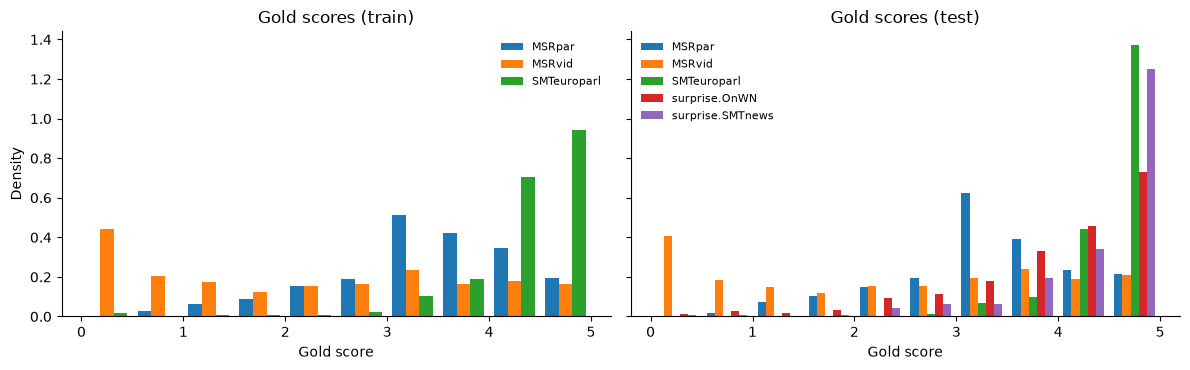

In [4]:
# Distribution of the gold scores of each dataset (train and test).
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
bins = np.linspace(0, 5, 11)
for ax, split, names in [(axes[0], "train", TRAIN_SETS), (axes[1], "test", TEST_SETS)]:
    values = [data[(split, n)][1] for n in names]
    ax.hist(values, bins=bins, label=names, density=True)
    ax.set_title(f"Gold scores ({split})")
    ax.set_xlabel("Gold score")
    ax.legend(fontsize=8, frameon=False)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

The datasets are very different. **MSRvid** pairs are short descriptions of videos with scores spread over the whole scale. **MSRpar** pairs are long news sentences, mostly paraphrases or near-paraphrases. **SMTeuroparl** pairs (and **SMTnews**) are a sentence and its machine translation, with almost all scores near 5. **OnWN** (surprise) pairs a sense definition from OntoNotes with a WordNet gloss. This heterogeneity is the main difficulty of the task: a single model has to work on all of them, and two of the test sets have no training data.

## 2. Evaluation and official results

The three official measures are implemented below and checked with the submissions of the participants: they reproduce the official results of the task (e.g. the baseline `tokencos` with ALL = 0.3110 and the 10th system with ALL = 0.7562, the two thresholds of the project grade).

In [5]:
def evaluate(predictions):
    """Official measures for a dict {test set: predicted scores}."""
    gold = {s: data[("test", s)][1] for s in TEST_SETS}
    all_gold = np.concatenate([gold[s] for s in TEST_SETS])
    result = {"ALL": pearsonr(all_gold, np.concatenate([predictions[s] for s in TEST_SETS]))[0]}
    # ALLnrm: each test set is first normalized with a least-squares fit to its gold standard.
    normalized = []
    for s in TEST_SETS:
        slope, intercept = np.polyfit(predictions[s], gold[s], 1)
        normalized.append(slope * predictions[s] + intercept)
    result["ALLnrm"] = pearsonr(all_gold, np.concatenate(normalized))[0]
    per_set = {s: pearsonr(gold[s], predictions[s])[0] for s in TEST_SETS}
    result["Mean"] = sum(per_set[s] * len(gold[s]) for s in TEST_SETS) / len(all_gold)
    return {**result, **per_set}

def read_submission(folder):
    """Scores of one submitted run (first column; some files have extra columns or blank lines,
    and a few contain "nan", which is counted as 0)."""
    predictions = {}
    for s in TEST_SETS:
        lines = (folder / f"STS.output.{s}.txt").read_text(encoding="utf-8", errors="replace").rstrip().split("\n")
        predictions[s] = np.nan_to_num(np.array([float(line.split()[0]) for line in lines]))
    return predictions

# Evaluate all the runs: the participants and the official baseline (tokencos).
# The random and constant baselines of the organizers are not part of the official ranking.
official = []
for folder in sorted(SUBMISSIONS_DIR.glob("*/*")):
    if not folder.is_dir() or folder.name == "__MACOSX":
        continue
    if folder.parent.name == "00-baseline" and folder.name != "task6-tokencos":
        continue
    official.append({"run": f"{folder.parent.name}/{folder.name.removeprefix('task6-')}",
                     **evaluate(read_submission(folder))})

official = pd.DataFrame(official).sort_values("ALL", ascending=False).reset_index(drop=True)
official.index += 1  # rank
print(f"Official runs (participants + baseline): {len(official)}")
official.head(12).round(4)

Official runs (participants + baseline): 89


,run,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews
1,baer/UKP-run2_plus_postprocessing_smt_twsi,0.8239,0.8579,0.6773,0.6830,0.8739,0.5280,0.6641,0.4937
2,jan_snajder/takelab-syntax,0.8138,0.8569,0.6601,0.6985,0.8620,0.3612,0.7049,0.4683
3,jan_snajder/takelab-simple,0.8133,0.8635,0.6753,0.7343,0.8803,0.4771,0.6797,0.3989
4,baer/UKP-run1,0.8116,0.8559,0.6708,0.6821,0.8708,0.5118,0.6649,0.4672
5,rada/UNT-IndividualRegression,0.7846,0.8440,0.6162,0.5353,0.8750,0.4203,0.6715,0.4033
6,mheilman/ETS-PERPphrases,0.7834,0.8089,0.6399,0.6397,0.7200,0.4850,0.7124,0.5312
7,mheilman/ETS-PERP,0.7808,0.8064,0.6305,0.6211,0.7210,0.4722,0.7080,0.5149
8,baer/UKP-run3_plus_random,0.7790,0.8166,0.4320,0.6830,0.8739,0.5280,-0.0620,-0.0520
9,rada/UNT-IndividualDecTree,0.7677,0.8389,0.5947,0.5693,0.8688,0.4203,0.6491,0.2256
10,yeh/SRIUBC-SYSTEM2,0.7562,0.8111,0.5858,0.6050,0.7939,0.4294,0.5870,0.3366


In [6]:
# The two thresholds of the project grade.
baseline = official[official["run"] == "00-baseline/tokencos"]
print(f"Baseline (tokencos): ALL = {baseline['ALL'].iloc[0]:.4f}, rank {baseline.index[0]}")
print(f"10th participant:    ALL = {official.loc[10, 'ALL']:.4f} ({official.loc[10, 'run']})")
print(f"Best system:         ALL = {official.loc[1, 'ALL']:.4f} ({official.loc[1, 'run']})")

Baseline (tokencos): ALL = 0.3110, rank 87
10th participant:    ALL = 0.7562 (yeh/SRIUBC-SYSTEM2)
Best system:         ALL = 0.8239 (baer/UKP-run2_plus_postprocessing_smt_twsi)


## 3. Preprocessing

Every sentence is processed once with NLTK: tokenization (`word_tokenize`), POS tagging (averaged perceptron tagger, Penn Treebank tags), lowercasing, lemmatization with the WordNet lemmatizer using the POS tag (as in Lab 3) and marking of stopwords and punctuation. Each token is stored with all these annotations, and the features of the next section are computed from them.

In [7]:
STOPWORDS = set(stopwords.words("english"))
LEMMATIZER = nltk.stem.WordNetLemmatizer()
PUNCTUATION = re.compile(r"^\W+$")

def wordnet_pos(tag):
    """Penn Treebank tag -> WordNet POS (None for the other categories)."""
    return {"N": wn.NOUN, "V": wn.VERB, "J": wn.ADJ, "R": wn.ADV}.get(tag[0])

def preprocess(sentence):
    tokens = []
    for word, tag in nltk.pos_tag(nltk.word_tokenize(sentence)):
        pos = wordnet_pos(tag)
        lower = word.lower()
        tokens.append({
            "word": word, "lower": lower, "tag": tag, "pos": pos,
            "lemma": LEMMATIZER.lemmatize(lower, pos) if pos else lower,
            "stop": lower in STOPWORDS, "punct": bool(PUNCTUATION.match(word)),
        })
    return tokens

start = time.time()
processed = {key: [(preprocess(s1), preprocess(s2)) for s1, s2 in pairs] for key, (pairs, gold) in data.items()}
print(f"Preprocessed {sum(len(v) for v in processed.values())} pairs in {time.time() - start:.1f} s\n")

pd.DataFrame(processed[("train", "MSRvid")][0][0])

Preprocessed 5342 pairs in 2.6 s



,word,lower,tag,pos,lemma,stop,punct
0,A,a,DT,NaN,a,True,False
1,man,man,NN,n,man,False,False
2,is,is,VBZ,v,be,True,False
3,riding,riding,VBG,v,rid,False,False
4,a,a,DT,NaN,a,True,False
5,bicycle,bicycle,NN,n,bicycle,False,False
6,.,.,.,NaN,.,False,True


## 4. Features

Each feature is a similarity (or a difference) between the two sentences of a pair. They are grouped in three families, which correspond to the three dimensions of the statement.

### 4.1 Lexical features

| Group | Features |
|---|---|
| Word overlap | Jaccard of words, lowercased words, lemmas and content lemmas (without stopwords and punctuation); Dice and containment of content lemmas |
| N-grams | Jaccard of lemma bigrams and trigrams; cosine of character 2- to 5-grams |
| Weighting and order | TF-IDF cosine of content lemmas (IDF from the training sentences only); longest common subsequence of lemmas |
| WordNet | Aligned word similarity (each content word matched with its most similar word of the other sentence, IDF-weighted, in both directions; Mihalcea et al., 2006) with the Path, Wu-Palmer and Lin similarities; Jaccard of the most frequent senses (as in Lab 6) |
| Numbers | Jaccard of the numbers, same numbers, one set included in the other |
| Length | Ratio of the number of content words; relative difference of length |

In [8]:
def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0

def dice(a, b):
    a, b = set(a), set(b)
    return 2 * len(a & b) / (len(a) + len(b)) if a or b else 1.0

def containment(a, b):
    a, b = set(a), set(b)
    return len(a & b) / min(len(a), len(b)) if a and b else float(a == b)

def ngrams(sequence, n):
    return [tuple(sequence[i:i + n]) for i in range(len(sequence) - n + 1)]

def cosine(a, b):
    """Cosine of two bags (lists) of items."""
    ca, cb = Counter(a), Counter(b)
    dot = sum(ca[k] * cb[k] for k in ca.keys() & cb.keys())
    norm = math.sqrt(sum(v * v for v in ca.values())) * math.sqrt(sum(v * v for v in cb.values()))
    return dot / norm if norm else 0.0

def lcs_length(a, b):
    table = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a)):
        for j in range(len(b)):
            table[i + 1][j + 1] = table[i][j] + 1 if a[i] == b[j] else max(table[i][j + 1], table[i + 1][j])
    return table[-1][-1]

def content(tokens):
    return [t for t in tokens if not t["stop"] and not t["punct"]]

In [9]:
# IDF of the lemmas, computed on the training sentences only.
train_sentences = [t for (split, _), pairs in processed.items() if split == "train" for pair in pairs for t in pair]
document_frequency = Counter(lemma for t in train_sentences for lemma in {x["lemma"] for x in t})
IDF = {w: math.log(len(train_sentences) / c) for w, c in document_frequency.items()}
MAX_IDF = math.log(len(train_sentences))  # for the words that never appear in the training data

def idf(lemma):
    return IDF.get(lemma, MAX_IDF)

# WordNet similarities between words (cached, because the same words appear many times).
BROWN_IC = wordnet_ic.ic("ic-brown.dat")

@lru_cache(maxsize=None)
def synsets(lemma, pos):
    return tuple(wn.synsets(lemma, pos))

@lru_cache(maxsize=None)
def word_similarity(lemma1, pos1, lemma2, pos2, measure):
    """Maximum similarity between the first 3 senses of two words of the same category."""
    if lemma1 == lemma2:
        return 1.0
    if pos1 != pos2:
        return 0.0
    best = 0.0
    for a in synsets(lemma1, pos1)[:3]:
        for b in synsets(lemma2, pos2)[:3]:
            if measure == "path":
                value = a.path_similarity(b)
            elif measure == "wup":
                value = a.wup_similarity(b)
            elif pos1 in (wn.NOUN, wn.VERB):  # Lin is only defined for nouns and verbs
                value = a.lin_similarity(b, BROWN_IC)
            else:
                value = 0.0
            best = max(best, value or 0.0)
    return best

def aligned_similarity(tokens1, tokens2, measure):
    """Each content word is aligned with its most similar word of the other sentence (IDF-weighted average),
    and the two directions are averaged."""
    c1, c2 = content(tokens1), content(tokens2)
    if not c1 or not c2:
        return 0.0
    def direction(a, b):
        scores = [max(word_similarity(x["lemma"], x["pos"], y["lemma"], y["pos"], measure) for y in b) for x in a]
        weights = [idf(x["lemma"]) for x in a]
        return np.average(scores, weights=weights)
    return (direction(c1, c2) + direction(c2, c1)) / 2

NUMBER = re.compile(r"^[+-]?\d[\d,.]*$")

def numbers(tokens):
    return {t["word"].replace(",", "") for t in tokens if NUMBER.match(t["word"])}

def most_frequent_senses(tokens):
    return {synsets(t["lemma"], t["pos"])[0] for t in tokens if t["pos"] and synsets(t["lemma"], t["pos"])}

In [10]:
def lexical_features(t1, t2):
    f = {}
    lemmas1, lemmas2 = [t["lemma"] for t in t1], [t["lemma"] for t in t2]
    content1, content2 = [t["lemma"] for t in content(t1)], [t["lemma"] for t in content(t2)]

    # Word overlap
    f["jaccard_words"] = jaccard([t["word"] for t in t1], [t["word"] for t in t2])
    f["jaccard_lower"] = jaccard([t["lower"] for t in t1], [t["lower"] for t in t2])
    f["jaccard_lemmas"] = jaccard(lemmas1, lemmas2)
    f["jaccard_content"] = jaccard(content1, content2)
    f["dice_content"] = dice(content1, content2)
    f["containment_content"] = containment(content1, content2)

    # N-grams of lemmas and of characters
    for n in (2, 3):
        f[f"jaccard_lemma_{n}grams"] = jaccard(ngrams(lemmas1, n), ngrams(lemmas2, n))
    text1, text2 = " ".join(t["lower"] for t in t1), " ".join(t["lower"] for t in t2)
    for n in (2, 3, 4, 5):
        f[f"cosine_char_{n}grams"] = cosine(ngrams(text1, n), ngrams(text2, n))

    # TF-IDF cosine and longest common subsequence
    v1, v2 = Counter(content1), Counter(content2)
    dot = sum(v1[w] * v2[w] * idf(w) ** 2 for w in v1.keys() & v2.keys())
    norm = math.sqrt(sum((c * idf(w)) ** 2 for w, c in v1.items())) * math.sqrt(sum((c * idf(w)) ** 2 for w, c in v2.items()))
    f["tfidf_cosine"] = dot / norm if norm else 0.0
    f["lcs_lemmas"] = lcs_length(lemmas1, lemmas2) / max(len(lemmas1), len(lemmas2))

    # WordNet
    for measure in ("path", "wup", "lin"):
        f[f"wordnet_{measure}"] = aligned_similarity(t1, t2, measure)
    f["jaccard_mfs_senses"] = jaccard(most_frequent_senses(t1), most_frequent_senses(t2))

    # Numbers
    n1, n2 = numbers(t1), numbers(t2)
    f["numbers_jaccard"] = jaccard(n1, n2)
    f["numbers_equal"] = float(n1 == n2)
    f["numbers_included"] = float(n1 <= n2 or n2 <= n1)

    # Length
    f["length_ratio"] = min(len(content1), len(content2)) / max(len(content1), len(content2), 1)
    f["length_difference"] = abs(len(t1) - len(t2)) / max(len(t1), len(t2))
    return f

t1, t2 = processed[("train", "MSRvid")][0]
pd.Series(lexical_features(t1, t2)).round(3).to_frame("value").T

,jaccard_words,jaccard_lower,jaccard_lemmas,jaccard_content,dice_content,containment_content,jaccard_lemma_2grams,jaccard_lemma_3grams,cosine_char_2grams,cosine_char_3grams,...,lcs_lemmas,wordnet_path,wordnet_wup,wordnet_lin,jaccard_mfs_senses,numbers_jaccard,numbers_equal,numbers_included,length_ratio,length_difference
value,0.75,0.714,0.714,0.5,0.667,0.667,0.5,0.429,0.869,0.81,...,0.857,1.0,1.0,1.0,0.6,1.0,1.0,1.0,1.0,0.0


### 4.2 Syntactic features (syntactic dimension alone)

These features only look at the syntactic analysis of the sentences, **not at the words**: they would give the same values for two sentences with the same structure and completely different words.

- **POS tags**: Jaccard and cosine of the POS unigrams, bigrams and trigrams; normalized edit distance between the two POS sequences; difference of the proportion of nouns, verbs, adjectives and adverbs.
- **Chunks**: a regular-expression chunker (NLTK `RegexpParser`, as in Lab 7) finds the NP, VP and PP chunks. Features: normalized edit distance between the sequences of chunk labels, cosine of the chunk labels, and relative difference of the number of chunks of each type.

NLTK has no pre-trained full parser (a PCFG learned from the treebank sample, as in Lab 8, is too slow and has a low coverage for these sentences), so chunking is used as a shallow syntactic analysis.

In [11]:
CHUNKER = nltk.RegexpParser(r"""
    NP: {<DT|PRP\$|POS>?<JJ.*|CD|VBN|VBG>*<NN.*>+}
        {<PRP>}
        {<DT>?<CD>+}
    PP: {<IN|TO><NP>}
    VP: {<MD>?<RB.*>*<VB.*>+<RP>?}
""")

def chunk(tokens):
    """List of (label, lemmas) for each chunk of the sentence (the words outside chunks are skipped)."""
    tree = CHUNKER.parse([(t["word"], t["tag"]) for t in tokens])
    chunks, i = [], 0
    for node in tree:
        size = len(node.leaves()) if isinstance(node, nltk.Tree) else 1
        if isinstance(node, nltk.Tree):
            chunks.append((node.label(), [t["lemma"] for t in tokens[i:i + size]]))
        i += size
    return chunks

def normalized_edit_distance(a, b):
    return nltk.edit_distance(a, b) / max(len(a), len(b), 1)

def syntactic_features(t1, t2, chunks1, chunks2):
    f = {}
    tags1, tags2 = [t["tag"] for t in t1], [t["tag"] for t in t2]
    for n in (1, 2, 3):
        f[f"jaccard_pos_{n}grams"] = jaccard(ngrams(tags1, n), ngrams(tags2, n))
        f[f"cosine_pos_{n}grams"] = cosine(ngrams(tags1, n), ngrams(tags2, n))
    f["pos_edit_distance"] = normalized_edit_distance(tags1, tags2)
    for coarse in ("N", "V", "J", "R"):
        r1 = sum(t.startswith(coarse) for t in tags1) / len(tags1)
        r2 = sum(t.startswith(coarse) for t in tags2) / len(tags2)
        f[f"proportion_difference_{coarse}"] = abs(r1 - r2)

    labels1, labels2 = [label for label, _ in chunks1], [label for label, _ in chunks2]
    f["chunk_edit_distance"] = normalized_edit_distance(labels1, labels2)
    f["cosine_chunk_labels"] = cosine(labels1, labels2)
    for label in ("NP", "VP", "PP"):
        a, b = labels1.count(label), labels2.count(label)
        f[f"difference_{label}"] = abs(a - b) / max(a, b, 1)
    return f

chunks1, chunks2 = chunk(t1), chunk(t2)
print(" ".join(t["word"] for t in t1), "->", chunks1)
print(" ".join(t["word"] for t in t2), "->", chunks2)
pd.Series(syntactic_features(t1, t2, chunks1, chunks2)).round(3).to_frame("value").T

A man is riding a bicycle . -> [('NP', ['a', 'man']), ('VP', ['be', 'rid']), ('NP', ['a', 'bicycle'])]
A man is riding a bike . -> [('NP', ['a', 'man']), ('VP', ['be', 'rid']), ('NP', ['a', 'bike'])]


,jaccard_pos_1grams,cosine_pos_1grams,jaccard_pos_2grams,cosine_pos_2grams,jaccard_pos_3grams,cosine_pos_3grams,pos_edit_distance,proportion_difference_N,proportion_difference_V,proportion_difference_J,proportion_difference_R,chunk_edit_distance,cosine_chunk_labels,difference_NP,difference_VP,difference_PP
value,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


### 4.3 Lexico-syntactic features (combination)

These features combine both dimensions: the words are compared **within the same syntactic category or role**.

- Jaccard of the lemmas of each category separately (nouns, verbs, adjectives, adverbs), and of the (lemma, coarse POS tag) pairs.
- Jaccard of the chunks represented by their label and head (last lemma of the chunk), and of the heads of the NPs and of the VPs separately.
- Word order: proportion of pairs of shared lemmas that appear in the same order in both sentences.

In [12]:
def lexico_syntactic_features(t1, t2, chunks1, chunks2):
    f = {}
    for coarse, name in [("N", "nouns"), ("V", "verbs"), ("J", "adjectives"), ("R", "adverbs")]:
        a = {t["lemma"] for t in t1 if t["tag"].startswith(coarse)}
        b = {t["lemma"] for t in t2 if t["tag"].startswith(coarse)}
        f[f"jaccard_{name}"] = jaccard(a, b)
    f["jaccard_lemma_tag"] = jaccard([(t["lemma"], t["tag"][:2]) for t in t1], [(t["lemma"], t["tag"][:2]) for t in t2])

    heads1 = [(label, lemmas[-1]) for label, lemmas in chunks1]
    heads2 = [(label, lemmas[-1]) for label, lemmas in chunks2]
    f["jaccard_chunk_heads"] = jaccard(heads1, heads2)
    for label in ("NP", "VP"):
        f[f"jaccard_{label}_heads"] = jaccard({h for l, h in heads1 if l == label}, {h for l, h in heads2 if l == label})

    lemmas1, lemmas2 = [t["lemma"] for t in t1], [t["lemma"] for t in t2]
    shared = [w for w in dict.fromkeys(lemmas1) if w in lemmas2]
    positions = [lemmas2.index(w) for w in shared]
    pairs = [(i, j) for i in range(len(positions)) for j in range(i + 1, len(positions))]
    f["word_order"] = sum(positions[i] < positions[j] for i, j in pairs) / len(pairs) if pairs else 1.0
    return f

pd.Series(lexico_syntactic_features(t1, t2, chunks1, chunks2)).round(3).to_frame("value").T

,jaccard_nouns,jaccard_verbs,jaccard_adjectives,jaccard_adverbs,jaccard_lemma_tag,jaccard_chunk_heads,jaccard_NP_heads,jaccard_VP_heads,word_order
value,0.333,1.0,1.0,1.0,0.714,0.5,0.333,1.0,1.0


In [13]:
# Compute all the features of every pair.
def features(t1, t2):
    chunks1, chunks2 = chunk(t1), chunk(t2)
    return ({f"lex:{k}": v for k, v in lexical_features(t1, t2).items()}
            | {f"syn:{k}": v for k, v in syntactic_features(t1, t2, chunks1, chunks2).items()}
            | {f"lexsyn:{k}": v for k, v in lexico_syntactic_features(t1, t2, chunks1, chunks2).items()})

start = time.time()
X = {key: pd.DataFrame([features(t1, t2) for t1, t2 in pairs]) for key, pairs in processed.items()}
y = {key: gold for key, (pairs, gold) in data.items()}
print(f"Features computed in {time.time() - start:.1f} s")

FEATURE_GROUPS = {
    "lexical": [c for c in X[("train", "MSRpar")].columns if c.startswith("lex:")],
    "syntactic": [c for c in X[("train", "MSRpar")].columns if c.startswith("syn:")],
}
FEATURE_GROUPS["combined"] = list(X[("train", "MSRpar")].columns)
print({group: len(columns) for group, columns in FEATURE_GROUPS.items()})

Features computed in 40.7 s
{'lexical': 23, 'syntactic': 16, 'combined': 48}


In [14]:
# Each feature alone, used directly as a similarity score: Pearson correlation with the gold standard
# on each training set. (A negative value means that the feature is a distance.)
# (Features that are constant in a dataset, e.g. the numbers in MSRvid, have no correlation: NaN.)
with np.errstate(invalid="ignore", divide="ignore"):
    single = pd.DataFrame({s: X[("train", s)].corrwith(pd.Series(y[("train", s)])) for s in TRAIN_SETS})
single["mean |r|"] = single.abs().mean(axis=1)
single["family"] = single.index.str.split(":").str[0]
print("Best features of each family (mean |Pearson| over the three training sets):")
single.sort_values("mean |r|", ascending=False).groupby("family").head(4).round(3)

Best features of each family (mean |Pearson| over the three training sets):


,MSRpar,MSRvid,SMTeuroparl,mean |r|,family
lex:wordnet_path,0.655,0.812,0.540,0.669,lex
lex:tfidf_cosine,0.630,0.794,0.471,0.632,lex
lex:wordnet_lin,0.661,0.737,0.491,0.630,lex
lex:dice_content,0.611,0.768,0.485,0.622,lex
lexsyn:jaccard_lemma_tag,0.529,0.505,0.498,0.511,lexsyn
lexsyn:jaccard_chunk_heads,0.388,0.638,0.367,0.465,lexsyn
lexsyn:jaccard_nouns,0.334,0.566,0.420,0.440,lexsyn
lexsyn:jaccard_NP_heads,0.257,0.462,0.287,0.335,lexsyn
syn:jaccard_pos_1grams,0.194,-0.154,0.507,0.285,syn
syn:cosine_pos_1grams,0.179,-0.038,0.598,0.272,syn


## 5. Model selection with cross-validation

The features are combined with a **regression model** trained on the gold scores. All the choices are made with a 5-fold cross-validation **on the training data only**; the test set is used only once the system is fixed (section 6).

Choices:

- **Feature set**: lexical, syntactic or combined (all).
- **Model**: support vector regression with RBF kernel (SVR, with standardized features), random forest (RF) and gradient boosting (GBR).
- **Training strategy**: one *single* model trained on the three training sets together, or one model *per dataset* (each test set is predicted by the model trained on the training set of the same source, as done by the best systems of the task). The surprise sets have no training data: OnWN is predicted with the single model, and SMTnews, which is also machine translation, with the SMTeuroparl model.

The cross-validation predictions of the 2234 training pairs are evaluated with the same measures as the test set (ALL, ALLnrm and Mean over the three training sets).

In [15]:
MODELS = {
    "SVR": lambda: make_pipeline(StandardScaler(), SVR(C=1.0, epsilon=0.2)),
    "RF": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=0),
    "GBR": lambda: GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                             subsample=0.8, random_state=0),
}

def scores(gold, predictions, sets):
    """ALL, ALLnrm and Mean for dicts {set: array}."""
    g = np.concatenate([gold[s] for s in sets])
    p = np.concatenate([predictions[s] for s in sets])
    normalized = np.concatenate([np.polyval(np.polyfit(predictions[s], gold[s], 1), predictions[s]) for s in sets])
    per_set = {s: pearsonr(gold[s], predictions[s])[0] for s in sets}
    return {"ALL": pearsonr(g, p)[0], "ALLnrm": pearsonr(g, normalized)[0],
            "Mean": sum(per_set[s] * len(gold[s]) for s in sets) / len(g), **per_set}

def cross_validate(columns, make_model, strategy, folds=5):
    """Cross-validation predictions for the three training sets.
    The same folds are used for both strategies: in each fold, the single model is trained on the
    training folds of the three sets, and the per-dataset models on the training folds of their own set."""
    split = {s: list(KFold(folds, shuffle=True, random_state=0).split(X[("train", s)])) for s in TRAIN_SETS}
    predictions = {s: np.zeros(len(y[("train", s)])) for s in TRAIN_SETS}
    for k in range(folds):
        if strategy == "single":
            model = make_model().fit(
                pd.concat([X[("train", s)].iloc[split[s][k][0]][columns] for s in TRAIN_SETS]),
                np.concatenate([y[("train", s)][split[s][k][0]] for s in TRAIN_SETS]))
        for s in TRAIN_SETS:
            train_idx, test_idx = split[s][k]
            if strategy == "per dataset":
                model = make_model().fit(X[("train", s)].iloc[train_idx][columns], y[("train", s)][train_idx])
            predictions[s][test_idx] = model.predict(X[("train", s)].iloc[test_idx][columns])
    return {s: np.clip(p, 0, 5) for s, p in predictions.items()}

start = time.time()
cv_results = []
for group, columns in FEATURE_GROUPS.items():
    for model_name, make_model in MODELS.items():
        for strategy in ["single", "per dataset"]:
            predictions = cross_validate(columns, make_model, strategy)
            cv_results.append({"features": group, "model": model_name, "strategy": strategy,
                               **scores({s: y[("train", s)] for s in TRAIN_SETS}, predictions, TRAIN_SETS)})
cv_results = pd.DataFrame(cv_results)
print(f"Cross-validation done in {time.time() - start:.0f} s")
cv_results.sort_values("ALL", ascending=False).round(4)

Cross-validation done in 46 s


,features,model,strategy,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl
15,combined,RF,per dataset,0.8872,0.8872,0.7674,0.7006,0.8589,0.7422
17,combined,GBR,per dataset,0.8832,0.8836,0.7622,0.6970,0.8514,0.7377
3,lexical,RF,per dataset,0.8826,0.8827,0.7603,0.7027,0.8491,0.7284
1,lexical,SVR,per dataset,0.8799,0.8801,0.7604,0.7149,0.8394,0.7260
5,lexical,GBR,per dataset,0.8791,0.8798,0.7541,0.6984,0.8446,0.7185
13,combined,SVR,per dataset,0.8787,0.8793,0.7556,0.6867,0.8435,0.7362
16,combined,GBR,single,0.8695,0.8790,0.7446,0.6803,0.8502,0.7022
14,combined,RF,single,0.8688,0.8798,0.7436,0.6819,0.8529,0.6949
12,combined,SVR,single,0.8682,0.8764,0.7377,0.6750,0.8469,0.6902
2,lexical,RF,single,0.8619,0.8762,0.7391,0.6932,0.8429,0.6801


In [16]:
# Best configuration of each feature set (by cross-validation ALL), and the selected system.
best_cv = cv_results.loc[cv_results.groupby("features")["ALL"].idxmax()].set_index("features")
SELECTED = best_cv["ALL"].idxmax()
print(f"Selected system: {SELECTED} features, {best_cv.loc[SELECTED, 'model']}, {best_cv.loc[SELECTED, 'strategy']}\n")
best_cv.loc[["lexical", "syntactic", "combined"]].round(4)

Selected system: combined features, RF, per dataset



,model,strategy,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl
features,,,,,,,,
lexical,RF,per dataset,0.8826,0.8827,0.7603,0.7027,0.8491,0.7284
syntactic,SVR,per dataset,0.6788,0.6846,0.4208,0.2364,0.3437,0.6880
combined,RF,per dataset,0.8872,0.8872,0.7674,0.7006,0.8589,0.7422


## 6. Results on the test set

Each configuration is now trained on the whole training data and evaluated on the five test sets. The **selected system** is the one chosen by cross-validation in the previous section; the other configurations are shown to compare the feature sets, models and strategies, not to choose among them.

In [17]:
SURPRISE_MODEL = {"surprise.OnWN": None, "surprise.SMTnews": "SMTeuroparl"}  # None: single model

def train_and_predict(columns, make_model, strategy):
    single = make_model().fit(pd.concat([X[("train", s)][columns] for s in TRAIN_SETS]),
                              np.concatenate([y[("train", s)] for s in TRAIN_SETS]))
    per_dataset = {s: make_model().fit(X[("train", s)][columns], y[("train", s)]) for s in TRAIN_SETS} \
        if strategy == "per dataset" else {}
    predictions = {}
    for s in TEST_SETS:
        source = s if s in TRAIN_SETS else SURPRISE_MODEL[s]
        model = per_dataset.get(source, single)
        predictions[s] = np.clip(model.predict(X[("test", s)][columns]), 0, 5)
    return predictions

test_predictions, test_results = {}, []
for group, columns in FEATURE_GROUPS.items():
    for model_name, make_model in MODELS.items():
        for strategy in ["single", "per dataset"]:
            predictions = train_and_predict(columns, make_model, strategy)
            test_predictions[(group, model_name, strategy)] = predictions
            test_results.append({"features": group, "model": model_name, "strategy": strategy, **evaluate(predictions)})
test_results = pd.DataFrame(test_results)

def official_rank(value, measure="ALL"):
    """Rank that a run with this score would have had in the official ranking (89 runs)."""
    return int((official[measure] > value).sum()) + 1

test_results["rank (ALL)"] = test_results["ALL"].map(official_rank)
test_results.round(4)

,features,model,strategy,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews,rank (ALL)
0,lexical,SVR,single,0.7755,0.8582,0.6815,0.6817,0.8585,0.4942,0.7261,0.4802,9
1,lexical,SVR,per dataset,0.8200,0.8600,0.6887,0.6962,0.8546,0.4533,0.7261,0.5628,2
2,lexical,RF,single,0.7717,0.8563,0.6815,0.6842,0.8605,0.5246,0.6922,0.4999,9
3,lexical,RF,per dataset,0.8193,0.8613,0.6950,0.6808,0.8682,0.5367,0.6922,0.5837,2
4,lexical,GBR,single,0.7741,0.8549,0.6724,0.6613,0.8622,0.4905,0.6944,0.5045,9
5,lexical,GBR,per dataset,0.8207,0.8580,0.6853,0.6671,0.8627,0.4995,0.6944,0.5826,2
6,syntactic,SVR,single,0.2560,0.6213,0.1427,0.1459,0.3140,-0.1759,0.1461,0.1750,89
7,syntactic,SVR,per dataset,0.5350,0.6310,0.2588,0.2344,0.3300,0.3022,0.1461,0.3327,60
8,syntactic,RF,single,0.3325,0.6214,0.1786,0.2328,0.2956,-0.0879,0.1588,0.2007,85
9,syntactic,RF,per dataset,0.5337,0.6371,0.2812,0.2875,0.3459,0.3093,0.1588,0.3455,60


In [18]:
# The selected system and the best of each feature set (chosen by cross-validation), on the test set.
chosen = [(group, best_cv.loc[group, "model"], best_cv.loc[group, "strategy"]) for group in ["lexical", "syntactic", "combined"]]
summary = test_results.set_index(["features", "model", "strategy"]).loc[chosen]
for measure in ["ALLnrm", "Mean"]:
    summary[f"rank ({measure})"] = summary[measure].map(lambda v: official_rank(v, measure))
SYSTEM = (SELECTED, best_cv.loc[SELECTED, "model"], best_cv.loc[SELECTED, "strategy"])
system_result = summary.loc[SYSTEM]
print(f"Selected system {SYSTEM}: ALL = {system_result['ALL']:.4f} (rank {int(system_result['rank (ALL)'])} of {len(official) + 1})")
summary.round(4)

Selected system ('combined', 'RF', 'per dataset'): ALL = 0.8217 (rank 2 of 90)


,,,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews,rank (ALL),rank (ALLnrm),rank (Mean)
features,model,strategy,,,,,,,,,,,
lexical,RF,per dataset,0.8193,0.8613,0.6950,0.6808,0.8682,0.5367,0.6922,0.5837,2,2,1
syntactic,SVR,per dataset,0.5350,0.6310,0.2588,0.2344,0.3300,0.3022,0.1461,0.3327,60,88,88
combined,RF,per dataset,0.8217,0.8631,0.6937,0.6791,0.8756,0.5358,0.6916,0.5644,2,2,1


In [19]:
# Comparison with the official ranking: our selected system inserted among the top runs and the baseline.
ours = {"run": f"OURS: {' / '.join(SYSTEM)}", **{k: system_result[k] for k in ["ALL", "ALLnrm", "Mean"] + TEST_SETS}}
comparison = pd.concat([official, pd.DataFrame([ours])]).sort_values("ALL", ascending=False).reset_index(drop=True)
comparison.index += 1
for measure in ["ALL", "ALLnrm", "Mean"]:
    best = official.loc[official[measure].idxmax()]
    print(f"Best official {measure:<6} {best[measure]:.4f} ({best['run']})   ours: {system_result[measure]:.4f}")
comparison[(comparison.index <= 12) | comparison["run"].str.contains("baseline")].round(4)

Best official ALL    0.8239 (baer/UKP-run2_plus_postprocessing_smt_twsi)   ours: 0.8217
Best official ALLnrm 0.8635 (jan_snajder/takelab-simple)   ours: 0.8631
Best official Mean   0.6773 (baer/UKP-run2_plus_postprocessing_smt_twsi)   ours: 0.6937


,run,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews
1,baer/UKP-run2_plus_postprocessing_smt_twsi,0.8239,0.8579,0.6773,0.6830,0.8739,0.5280,0.6641,0.4937
2,OURS: combined / RF / per dataset,0.8217,0.8631,0.6937,0.6791,0.8756,0.5358,0.6916,0.5644
3,jan_snajder/takelab-syntax,0.8138,0.8569,0.6601,0.6985,0.8620,0.3612,0.7049,0.4683
4,jan_snajder/takelab-simple,0.8133,0.8635,0.6753,0.7343,0.8803,0.4771,0.6797,0.3989
5,baer/UKP-run1,0.8116,0.8559,0.6708,0.6821,0.8708,0.5118,0.6649,0.4672
6,rada/UNT-IndividualRegression,0.7846,0.8440,0.6162,0.5353,0.8750,0.4203,0.6715,0.4033
7,mheilman/ETS-PERPphrases,0.7834,0.8089,0.6399,0.6397,0.7200,0.4850,0.7124,0.5312
8,mheilman/ETS-PERP,0.7808,0.8064,0.6305,0.6211,0.7210,0.4722,0.7080,0.5149
9,baer/UKP-run3_plus_random,0.7790,0.8166,0.4320,0.6830,0.8739,0.5280,-0.0620,-0.0520
10,rada/UNT-IndividualDecTree,0.7677,0.8389,0.5947,0.5693,0.8688,0.4203,0.6491,0.2256


**Our selected system (combined features, random forest, one model per dataset) reaches ALL = 0.8217**, which would be the **2nd of the 89 official runs**, only 0.0022 below the best system (UKP, 0.8239), and above the 10th participant (0.7562) that gives the maximum grade for the results. It is 1st on the Mean measure (0.6937, against 0.6773 for the best official run) and 2nd on ALLnrm (0.8631, against 0.8635 for TakeLab).

Note that this comparison is favourable to us: the participants did not have the test gold standard, while we could design our features knowing the papers of the best systems. However, no decision was taken by looking at the test set: the features, the model and the strategy were all chosen by cross-validation on the training data, and the configuration selected in this way is also the best of the 18 on the test set.

The three dimensions behave very differently:

| Features (best configuration by CV) | CV ALL (train) | Test ALL | Rank (ALL) |
|---|---|---|---|
| Lexical (RF, per dataset) | 0.8826 | 0.8193 | 2 |
| Syntactic alone (SVR, per dataset) | 0.6788 | 0.5350 | 60 |
| Combined (RF, per dataset) | 0.8872 | 0.8217 | 2 |

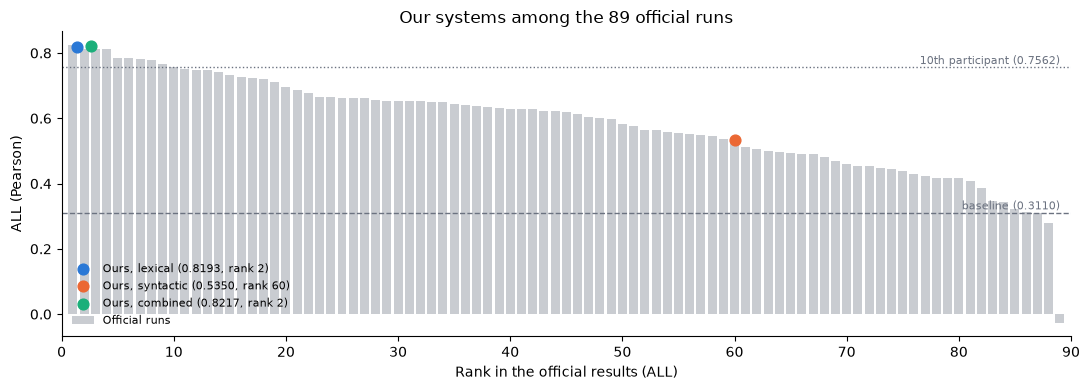

In [20]:
# Official ALL of every run, with our three systems (best lexical, syntactic and combined).
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(1, len(official) + 1), official["ALL"], color="#c9ccd1", width=0.8, label="Official runs")
ax.axhline(official.loc[10, "ALL"], color="#6b7280", linestyle=":", linewidth=1)
ax.text(len(official), official.loc[10, "ALL"] + 0.01, "10th participant (0.7562)", ha="right", fontsize=8, color="#6b7280")
ax.axhline(baseline["ALL"].iloc[0], color="#6b7280", linestyle="--", linewidth=1)
ax.text(len(official), baseline["ALL"].iloc[0] + 0.01, "baseline (0.3110)", ha="right", fontsize=8, color="#6b7280")
colors = {"lexical": "#2a78d6", "syntactic": "#eb6834", "combined": "#1baf7a"}
for group, model_name, strategy in chosen:
    value = summary.loc[(group, model_name, strategy), "ALL"]
    rank = official_rank(value)
    offset = {"lexical": -0.6, "syntactic": 0, "combined": 0.6}[group]  # lexical and combined have the same rank
    ax.scatter(rank + offset, value, color=colors[group], s=60, zorder=3, label=f"Ours, {group} ({value:.4f}, rank {rank})")
ax.set_xlabel("Rank in the official results (ALL)")
ax.set_ylabel("ALL (Pearson)")
ax.set_title("Our systems among the 89 official runs")
ax.set_xlim(0, len(official) + 1)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

## 7. Analysis

### 7.1 Results by dataset, compared with the best systems

In [21]:
# Pearson on each test set: our three systems, the two best participants and the baseline.
top_runs = ["baer/UKP-run2_plus_postprocessing_smt_twsi", "jan_snajder/takelab-simple", "00-baseline/tokencos"]
by_dataset = pd.concat([
    summary.reset_index().assign(run=lambda d: "OURS " + d["features"]).set_index("run")[TEST_SETS + ["ALL"]],
    official.set_index("run").loc[top_runs, TEST_SETS + ["ALL"]],
])
by_dataset.round(4)

,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews,ALL
run,,,,,,
OURS lexical,0.6808,0.8682,0.5367,0.6922,0.5837,0.8193
OURS syntactic,0.2344,0.3300,0.3022,0.1461,0.3327,0.5350
OURS combined,0.6791,0.8756,0.5358,0.6916,0.5644,0.8217
baer/UKP-run2_plus_postprocessing_smt_twsi,0.6830,0.8739,0.5280,0.6641,0.4937,0.8239
jan_snajder/takelab-simple,0.7343,0.8803,0.4771,0.6797,0.3989,0.8133
00-baseline/tokencos,0.4334,0.2996,0.4542,0.5864,0.3908,0.3110


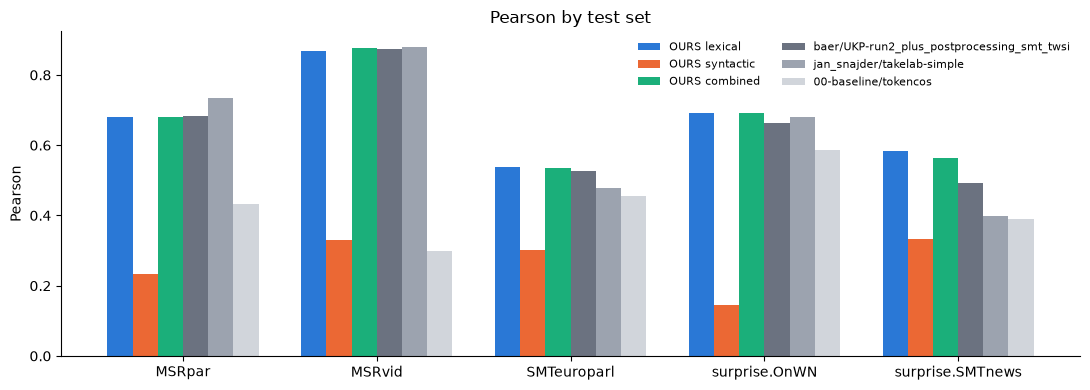

In [22]:
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.13
runs = list(by_dataset.index)
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6b7280", "#9ca3af", "#d1d5db"]
for i, run in enumerate(runs):
    ax.bar(np.arange(len(TEST_SETS)) + (i - len(runs) / 2 + 0.5) * width, by_dataset.loc[run, TEST_SETS],
           width, label=run, color=palette[i])
ax.set_xticks(range(len(TEST_SETS)), TEST_SETS)
ax.set_ylabel("Pearson")
ax.set_title("Pearson by test set")
ax.axhline(0, color="black", linewidth=0.5)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

- **Our combined system is better than the best official system (UKP) on four of the five test sets**: MSRvid (0.8756 vs 0.8739), SMTeuroparl (0.5358 vs 0.5280), OnWN (0.6916 vs 0.6641) and especially SMTnews (0.5644 vs 0.4937). It is slightly worse on MSRpar (0.6791 vs 0.6830), where TakeLab is clearly better (0.7343).
- **MSRvid is the easiest set** (0.8756): short sentences with the same simple structure, where the overlap of the content words and their WordNet similarity is very informative.
- **The machine translation sets (SMTeuroparl and SMTnews) are the hardest** for all the systems: their gold scores are concentrated between 4 and 5 (section 1), so small errors change the ranking of the pairs a lot, and the second sentence is often ungrammatical.
- **The surprise sets work reasonably well without training data of their own** (OnWN 0.6916, SMTnews 0.5644), which shows that the features generalize across sources.

### 7.2 Single model or one model per dataset?

In [23]:
# Effect of the training strategy for the selected features and model (test set).
strategy_effect = test_results[(test_results["features"] == SYSTEM[0]) & (test_results["model"] == SYSTEM[1])]
strategy_effect.set_index("strategy")[["ALL", "ALLnrm", "Mean"] + TEST_SETS].round(4)

,ALL,ALLnrm,Mean,MSRpar,MSRvid,SMTeuroparl,surprise.OnWN,surprise.SMTnews
strategy,,,,,,,,
single,0.7762,0.8571,0.6842,0.6848,0.8622,0.5436,0.6916,0.4964
per dataset,0.8217,0.8631,0.6937,0.6791,0.8756,0.5358,0.6916,0.5644


In [24]:
# ALL is a Pearson over the five test sets together, so it also depends on the scores being on the
# same scale across datasets. Mean predicted score of each test set, compared with the gold mean.
calibration = pd.DataFrame({
    "gold mean": {s: y[("test", s)].mean() for s in TEST_SETS},
    "single": {s: test_predictions[(SYSTEM[0], SYSTEM[1], "single")][s].mean() for s in TEST_SETS},
    "per dataset": {s: test_predictions[(SYSTEM[0], SYSTEM[1], "per dataset")][s].mean() for s in TEST_SETS},
})
calibration.round(3)

,gold mean,single,per dataset
MSRpar,3.271,3.450,3.278
MSRvid,2.297,2.289,2.259
SMTeuroparl,4.550,3.823,4.231
surprise.OnWN,3.871,3.123,3.123
surprise.SMTnews,4.335,3.672,4.133


**One model per dataset improves ALL by 0.0455 (0.7762 → 0.8217), but ALLnrm only by 0.0060 and Mean by 0.0095.** The per-dataset strategy does not rank the pairs inside each test set much better; its main effect is on the **scale** of the predictions. ALL concatenates the five test sets, so it also rewards predicting the right average level for each dataset. The single model learns an average of the three training sets and under-predicts the machine translation sets, where almost all the pairs are near 5: the mean prediction for SMTeuroparl is 3.823 (gold 4.550) and for SMTnews 3.672 (gold 4.335). The SMTeuroparl model, trained only on high scores, predicts 4.231 and 4.133. This is why the ranking on ALL is more sensitive to the training strategy than ALLnrm and Mean, and why the best systems of the task also trained separate models. OnWN uses the single model in both strategies, so its predictions do not change (mean 3.123 for a gold mean of 3.871).

### 7.3 Which features matter?

In [25]:
# Ablation: remove one group of features from the combined set and train the selected model and strategy again.
ABLATION_GROUPS = {
    "word overlap": ["lex:jaccard_words", "lex:jaccard_lower", "lex:jaccard_lemmas", "lex:jaccard_content",
                     "lex:dice_content", "lex:containment_content"],
    "n-grams (lemma and char)": [c for c in FEATURE_GROUPS["combined"] if "grams" in c and c.startswith("lex:")],
    "tf-idf and LCS": ["lex:tfidf_cosine", "lex:lcs_lemmas"],
    "WordNet": [c for c in FEATURE_GROUPS["combined"] if "wordnet" in c or "mfs" in c],
    "numbers": [c for c in FEATURE_GROUPS["combined"] if "numbers" in c],
    "length": ["lex:length_ratio", "lex:length_difference"],
    "syntactic (all)": FEATURE_GROUPS["syntactic"],
    "lexico-syntactic (all)": [c for c in FEATURE_GROUPS["combined"] if c.startswith("lexsyn:")],
}
assert sorted(sum(ABLATION_GROUPS.values(), [])) == sorted(FEATURE_GROUPS["combined"])

reference = evaluate(train_and_predict(FEATURE_GROUPS["combined"], MODELS[SYSTEM[1]], SYSTEM[2]))
ablation = []
for name, removed in ABLATION_GROUPS.items():
    columns = [c for c in FEATURE_GROUPS["combined"] if c not in removed]
    result = evaluate(train_and_predict(columns, MODELS[SYSTEM[1]], SYSTEM[2]))
    ablation.append({"removed group": name, "features": len(removed),
                     **{f"Δ {m}": result[m] - reference[m] for m in ["ALL", "Mean"] + TEST_SETS}})
print(f"Combined features, {SYSTEM[1]}, {SYSTEM[2]}: ALL = {reference['ALL']:.4f}, Mean = {reference['Mean']:.4f}")
pd.DataFrame(ablation).set_index("removed group").sort_values("Δ ALL").round(4)

Combined features, RF, per dataset: ALL = 0.8217, Mean = 0.6937


,features,Δ ALL,Δ Mean,Δ MSRpar,Δ MSRvid,Δ SMTeuroparl,Δ surprise.OnWN,Δ surprise.SMTnews
removed group,,,,,,,,
WordNet,4,-0.0081,-0.0068,0.0092,-0.0182,-0.0332,-0.0007,0.0038
length,2,-0.0044,-0.0178,-0.0022,-0.0007,-0.0437,-0.0045,-0.0746
numbers,3,-0.0034,-0.0051,-0.0218,0.0001,0.0000,-0.0024,0.0054
n-grams (lemma and char),6,-0.0025,-0.0155,-0.0139,-0.0028,-0.0351,-0.0153,-0.0199
lexico-syntactic (all),9,-0.0013,-0.0028,0.0006,-0.0066,-0.0034,-0.0020,-0.0025
tf-idf and LCS,2,-0.0012,0.0033,0.0005,-0.0051,0.0128,0.0045,0.0107
word overlap,6,0.0004,0.0014,0.0010,0.0000,-0.0019,-0.0007,0.0124
syntactic (all),16,0.0005,0.0036,-0.0018,0.0020,0.0073,0.0002,0.0189


                             MSRpar  MSRvid  SMTeuroparl
lex:wordnet_path              0.029   0.271       -0.026
lex:tfidf_cosine              0.003   0.203        0.006
lex:wordnet_lin               0.098   0.019        0.034
lex:numbers_included          0.049   0.000        0.000
lex:length_ratio              0.006   0.001        0.039
lexsyn:jaccard_chunk_heads   -0.002  -0.000        0.022
lexsyn:jaccard_lemma_tag      0.000   0.001        0.018
syn:proportion_difference_V   0.000  -0.000        0.018
lexsyn:jaccard_nouns          0.003   0.018       -0.005
lexsyn:jaccard_NP_heads      -0.000   0.001        0.016
lex:jaccard_lemmas            0.005  -0.000        0.014
syn:cosine_pos_1grams        -0.001   0.000        0.014


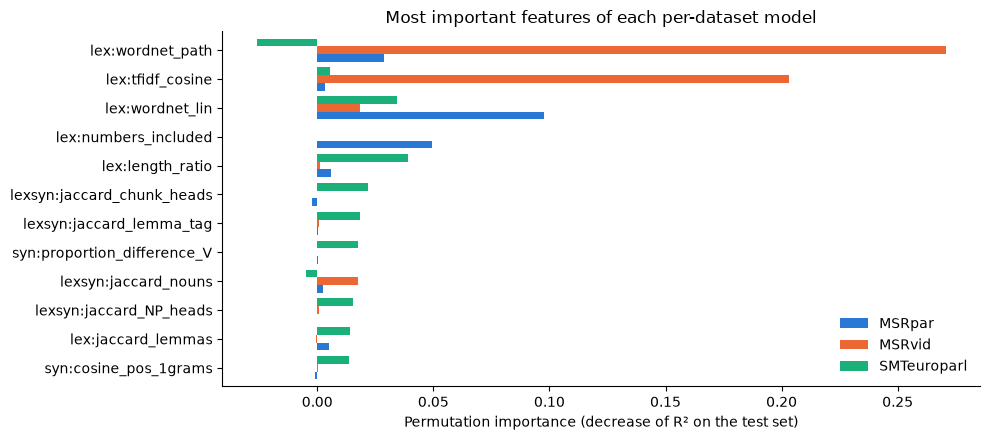

In [26]:
# Permutation importance of each feature for the model of each training set (combined features),
# measured on the corresponding test set (decrease of R² when the feature is shuffled).
importances = {}
for s in TRAIN_SETS:
    model = MODELS[SYSTEM[1]]().fit(X[("train", s)][FEATURE_GROUPS["combined"]], y[("train", s)])
    result = permutation_importance(model, X[("test", s)][FEATURE_GROUPS["combined"]], y[("test", s)],
                                    n_repeats=5, random_state=0, n_jobs=-1)
    importances[s] = pd.Series(result.importances_mean, index=FEATURE_GROUPS["combined"])
importances = pd.DataFrame(importances)
top = importances.loc[importances.max(axis=1).sort_values(ascending=False).index[:12]]
print(top.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
top[::-1].plot.barh(ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a"], width=0.8)
ax.set_xlabel("Permutation importance (decrease of R² on the test set)")
ax.set_title("Most important features of each per-dataset model")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lexical features carry almost all the information.** The best individual features are lexical: the WordNet aligned similarity with the Path measure (mean Pearson 0.669 over the training sets), the TF-IDF cosine (0.632) and the WordNet Lin similarity (0.630). In the ablation, removing the **WordNet** features costs the most (ALL -0.0081, SMTeuroparl -0.0332): they match synonyms and related words that word overlap misses. Some groups are important for a single dataset: the **length** features for the translation sets (SMTnews -0.0746, SMTeuroparl -0.0437), where a bad translation is often shorter or longer than the source, and the **numbers** for MSRpar (-0.0218), the news set with many figures. The permutation importance confirms it: `numbers_included` is the 2nd most important feature of the MSRpar model (after `wordnet_lin`), and `length_ratio` the most important one of the SMTeuroparl model.

**The syntactic dimension alone is weak** (test ALL 0.5350, rank 60, although still well above the baseline 0.3110). Two sentences with the same structure can mean completely different things. This is clear in MSRvid, where most sentences have the same pattern (*"A man is V-ing a N"*): the overlap of POS unigrams is even *negatively* correlated with the gold score there (-0.154), because the pairs with different structures are often the paraphrases. Syntax alone works better on SMTeuroparl in cross-validation (0.6880), where a bad translation tends to have a broken structure, but this does not transfer to the test set (0.3022).

**The combination adds little over the lexical features** (test ALL 0.8193 → 0.8217, CV 0.8826 → 0.8872). In the ablation, removing all the purely syntactic features does not hurt (ALL +0.0005), while removing the lexico-syntactic features costs a little (-0.0013): syntax is useful mainly to *restrict* the lexical comparison (words compared within the same category or chunk, e.g. `jaccard_chunk_heads` and `jaccard_lemma_tag` in the SMTeuroparl model), not as an independent signal. With only shallow syntax (POS tags and chunks) and no full parser, the structural information is limited.

### 7.4 Error analysis

In [27]:
# Largest errors of the selected system on each test set.
system_predictions = test_predictions[SYSTEM]
for s in TEST_SETS:
    pairs, gold = data[("test", s)]
    errors = system_predictions[s] - gold
    print(f"=== {s}: mean absolute error {np.abs(errors).mean():.3f}")
    for i in [int(np.argmax(errors)), int(np.argmin(errors))]:
        print(f"  gold {gold[i]:.2f}  predicted {system_predictions[s][i]:.2f}")
        print(f"    S1: {pairs[i][0]}")
        print(f"    S2: {pairs[i][1]}")
    print()

=== MSRpar: mean absolute error 0.525
  gold 1.40  predicted 3.70
    S1: RT Jones analyst Juli Niemann said Grant was "the one we were all pulling for.
    S2: He has a very good reputation," RT Jones analyst Juli Niemann said of Grant.
  gold 3.75  predicted 1.61
    S1: The Nasdaq composite index rose 13.70, or 0.8 per cent, to 1700.34.
    S2: The technology-laced Nasdaq Composite Index .IXIC gained 13.73 points, or 0.81 percent, to finish at 1,700.34.

=== MSRvid: mean absolute error 0.571
  gold 0.50  predicted 2.88
    S1: Two little girls are talking on the phone.
    S2: A little girl is walking down the street.
  gold 4.00  predicted 0.32
    S1: A woman puts cosmetics on her eyelid.
    S2: The woman is pencilling on eye shadow.

=== SMTeuroparl: mean absolute error 0.453
  gold 3.00  predicted 4.50
    S1: The standards are scarcely comparable, let alone transferable.
    S2: The rules are comparable only good, let alone.
  gold 4.50  predicted 1.96
    S1: The vote will ta

In [28]:
# Mean prediction for each range of gold scores: the system compresses the scale towards the
# training average (over-predicts the dissimilar pairs and under-predicts the equivalent ones).
all_gold = np.concatenate([y[("test", s)] for s in TEST_SETS])
all_pred = np.concatenate([system_predictions[s] for s in TEST_SETS])
ranges = pd.cut(all_gold, [0, 1, 2, 3, 4, 5], include_lowest=True)
pd.DataFrame({"gold": all_gold, "predicted": all_pred}).groupby(ranges, observed=True).agg(
    pairs=("gold", "size"), mean_gold=("gold", "mean"), mean_predicted=("predicted", "mean")).round(3)

,pairs,mean_gold,mean_predicted
"(-0.001, 1.0]",288,0.402,0.776
"(1.0, 2.0]",203,1.648,2.125
"(2.0, 3.0]",430,2.680,2.827
"(3.0, 4.0]",915,3.636,3.350
"(4.0, 5.0]",1272,4.692,4.048


The largest errors show the limits of a feature-based system without semantic representations of the whole sentence:

- **High overlap, different meaning.** MSRvid *"Two little girls are talking on the phone"* / *"A little girl is walking down the street"* (gold 0.50, predicted 2.88) and OnWN *"(Cause to) smell bad"* / *"be extremely bad in quality..."* (gold 0.00, predicted 2.73): they share words (*little girl*, *bad*), but the main event is different.
- **Paraphrases without shared words.** OnWN *"Bring back to life, return from the dead"* / *"cause to become alive again"* (gold 4.75, predicted 0.11), MSRvid *"A woman puts cosmetics on her eyelid"* / *"The woman is pencilling on eye shadow"* (gold 4.00, predicted 0.32) and SMTnews *"Other ways are needed"* / *"It is necessary to find other means"* (gold 4.50, predicted 1.68). WordNet only relates single words, so it cannot match *bring back to life* with *become alive again*.
- **Different formats of the same information.** *"5.30 p.m."* / *"17h30"* in SMTeuroparl (gold 4.50, predicted 1.96), and in MSRpar *13.70* / *13.73* and *0.8 per cent* / *0.81 percent* (gold 3.75, predicted 1.61): the numbers are compared as strings, so rounded or reformatted values do not match.
- **Ungrammatical translations.** SMTeuroparl *"The rules are comparable only good, let alone."* (gold 3.00, predicted 4.50): it shares most content words with the source, but it lost part of the meaning.

Finally, the predictions are **compressed towards the middle of the scale**: the pairs with a gold score up to 1 get a mean prediction of 0.776 (gold 0.402), and those above 4 a mean of 4.048 (gold 4.692). This is the usual behaviour of a regression model trained with a squared error (and of random forests, which average the training targets), and it does not affect the Pearson correlation much, as it is a monotonic effect.

## 8. Conclusions

- We built an STS system with NLTK only, combining 48 similarity features with a regression model. The **combined system reaches ALL = 0.8217 (2nd of 89 official runs), ALLnrm = 0.8631 (2nd) and Mean = 0.6937 (1st)**, well above the baseline (0.3110) and the 10th participant (0.7562).
- **The lexical dimension is the core of the system** (0.8193 alone). The most useful information comes from WordNet word similarities, TF-IDF weighting, and dataset-specific signals such as numbers and length.
- **The syntactic dimension alone is not enough** (0.5350): the same structure can carry different meanings. Combined with the lexical features, it adds a small improvement (+0.0024 on ALL), mainly through the lexico-syntactic features that compare words within the same category or chunk.
- **The training strategy matters as much as the features for ALL**: one model per dataset improves ALL by 0.0455, mostly by predicting the right score level for each dataset, as shown by ALLnrm and Mean.
- **Main limitations**: paraphrases with no shared words (multiword expressions), different formats of numbers and times, and the lack of a full syntactic parse. Possible improvements without embeddings: normalizing numbers, dates and times; aligning multiword expressions with WordNet; adding a dependency or constituency parser to compare the predicate-argument structure; and tuning the hyperparameters of the models with cross-validation.